In [187]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

In [188]:
df=pd.read_csv('E-commerse.csv')

In [189]:
df.head()

,Order_ID,Customer_ID,Customer_Name,Gender,Age,Region,City,Order_Date,Product_Category,Product_Name,Quantity,Unit_Price,Discount,Revenue,Payment_Method,Delivery_Status,Customer_Rating,Marketing_Channel
0,ORD1000,NaN,Priya Patel,F,0.0,North,Delhi,2025-03-13,Electronic,Laptop,5,"1,499",15,0,upi,delivered,5.0,NaN
1,ORD1001,C151,Riya Shah,Male,31.0,East,Lucknow,04/23/25,Electronics,Headphones,4,7999,-5,2500,upi,delivered,3.0,Instagram
2,ORD1002,C207,Rahul Sharma,FEMALE,150.0,west,Mumbai,"Nov 06,2025",Electronic,Smartphone,2,2500,120,5000,UPI,Cancelled,3.0,NaN
3,ORD1003,C021,Neha Gupta,Male,0.0,South,NaN,"Jan 31,2026",Beauty,Face Wash,2,₹999,15,-500,Card,delivered,3.0,Google Ads
4,ORD1004,C042,Vikram Das,Female,60.0,west,Pune,01-10-2025,Fashion,Jeans,5,₹999,10,-500,Card,Delivered,2.0,Instagram


In [190]:
df.describe()

,Age,Quantity,Revenue,Customer_Rating
count,890.000000,1000.000000,1000.000000,827.000000
mean,40.491011,8.979000,6647.353000,3.000000
std,45.811302,15.884485,9841.545115,1.403041
min,-4.000000,-1.000000,-500.000000,1.000000
25%,0.000000,1.000000,0.000000,2.000000
50%,25.000000,3.000000,2500.000000,3.000000
75%,45.000000,5.000000,12000.000000,4.000000
max,150.000000,50.000000,30000.000000,5.000000


In [191]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           1000 non-null   str    
 1   Customer_ID        986 non-null    str    
 2   Customer_Name      1000 non-null   str    
 3   Gender             1000 non-null   str    
 4   Age                890 non-null    float64
 5   Region             1000 non-null   str    
 6   City               883 non-null    str    
 7   Order_Date         1000 non-null   str    
 8   Product_Category   1000 non-null   str    
 9   Product_Name       1000 non-null   str    
 10  Quantity           1000 non-null   int64  
 11  Unit_Price         1000 non-null   str    
 12  Discount           874 non-null    str    
 13  Revenue            1000 non-null   int64  
 14  Payment_Method     1000 non-null   str    
 15  Delivery_Status    1000 non-null   str    
 16  Customer_Rating    827 non-null    f

## 1. Represnt total count of null value present in the entire datasets.

In [192]:
print(df.shape)

(1000, 18)


In [193]:
df.isnull().sum()

Order_ID               0
Customer_ID           14
Customer_Name          0
Gender                 0
Age                  110
Region                 0
City                 117
Order_Date             0
Product_Category       0
Product_Name           0
Quantity               0
Unit_Price             0
Discount             126
Revenue                0
Payment_Method         0
Delivery_Status        0
Customer_Rating      173
Marketing_Channel    209
dtype: int64

In [194]:
print(df.dtypes)

Order_ID                 str
Customer_ID              str
Customer_Name            str
Gender                   str
Age                  float64
Region                   str
City                     str
Order_Date               str
Product_Category         str
Product_Name             str
Quantity               int64
Unit_Price               str
Discount                 str
Revenue                int64
Payment_Method           str
Delivery_Status          str
Customer_Rating      float64
Marketing_Channel        str
dtype: object


## 2.we did conversion of the discount value string into integer.

In [195]:
df["Discount"] = df["Discount"].astype(str).str.replace("%", "", regex=False)
df["Discount"] = pd.to_numeric(df["Discount"], errors="coerce")

In [196]:
print(df["Discount"].unique)

<bound method Series.unique of 0       15.0
1       -5.0
2      120.0
3       15.0
4       10.0
       ...  
995      0.0
996      NaN
997      NaN
998      5.0
999    120.0
Name: Discount, Length: 1000, dtype: float64>


In [197]:
df["Discount"].value_counts(dropna=False)

Discount
 5.0      137
 15.0     134
 10.0     134
 120.0    130
-5.0      128
 NaN      126
 0.0      106
 20.0     105
Name: count, dtype: int64

In [198]:
df.describe()

,Age,Quantity,Discount,Revenue,Customer_Rating
count,890.000000,1000.000000,874.000000,1000.000000,827.000000
mean,40.491011,8.979000,24.136156,6647.353000,3.000000
std,45.811302,15.884485,40.825149,9841.545115,1.403041
min,-4.000000,-1.000000,-5.000000,-500.000000,1.000000
25%,0.000000,1.000000,0.000000,0.000000,2.000000
50%,25.000000,3.000000,10.000000,2500.000000,3.000000
75%,45.000000,5.000000,20.000000,12000.000000,4.000000
max,150.000000,50.000000,120.000000,30000.000000,5.000000


In [199]:
df["Unit_Price"] = df["Unit_Price"].astype(str).str.replace("%", "", regex=False)
df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce")

In [200]:
print(df["Unit_Price"].unique)

<bound method Series.unique of 0         NaN
1      7999.0
2      2500.0
3         NaN
4         NaN
        ...  
995       NaN
996       NaN
997       NaN
998       NaN
999       NaN
Name: Unit_Price, Length: 1000, dtype: float64>


## 3. Handled Missing Values.

In [201]:
df["Customer_ID"] = df["Customer_ID"].fillna("Unknown")

df["Age"] = df["Age"].fillna(df["Age"].median())

df["City"] = df["City"].fillna(df["City"].mode()[0])

df["Discount"] = df["Discount"].fillna(0)

df["Customer_Rating"] = df["Customer_Rating"].fillna(df["Customer_Rating"].mean())

df["Marketing_Channel"] = df["Marketing_Channel"].fillna("Unknown")






In [202]:
df.isnull().sum()

Order_ID               0
Customer_ID            0
Customer_Name          0
Gender                 0
Age                    0
Region                 0
City                   0
Order_Date             0
Product_Category       0
Product_Name           0
Quantity               0
Unit_Price           590
Discount               0
Revenue                0
Payment_Method         0
Delivery_Status        0
Customer_Rating        0
Marketing_Channel      0
dtype: int64

In [203]:
df["Unit_Price"] = df["Unit_Price"].fillna(df["Unit_Price"].median())

In [204]:
median_qty = df[(df["Quantity"] > 0) & (df["Quantity"] <= 20)]["Quantity"].median()

df.loc[(df["Quantity"] <= 0) | (df["Quantity"] > 20), "Quantity"] = median_qty

In [205]:
median_discount = df[(df["Discount"] >=0) & (df["Discount"]<=100)]["Discount"].median()

df.loc[(df["Discount"] <0) | (df["Discount"]>100), "Discount"] = median_discount

In [206]:
median_age = df[(df["Age"] >=18) & (df["Age"]<=100)]["Age"].median()

df.loc[(df["Age"] <18) | (df["Age"]>100), "Age"] = median_age

In [207]:
df = df[df["Revenue"] >= 0]

In [208]:
print(df['Payment_Method'].unique())

<StringArray>
['upi', 'UPI', 'Wallet', 'Cash', 'Card']
Length: 5, dtype: str


In [209]:
print(df['Region'].unique())

<StringArray>
['North', 'East', 'west', 'NORTH', 'Nrth', 'West', 'South', 'south', 'north']
Length: 9, dtype: str


In [210]:
df["Region"] = df["Region"].replace({"Nrth": "North","NORTH": "North","north": "North","south":"South","west":"West"})

In [211]:
print(df['City'].unique())

<StringArray>
['Delhi', 'Lucknow', ' Mumbai', 'Jaipur', 'Bhopal', 'Ahmedabad ', 'Pune']
Length: 7, dtype: str


In [212]:
print(df['Unit_Price'].unique())

[7999. 2500.]


In [213]:
print(df['Delivery_Status'].unique())

<StringArray>
['delivered', 'Cancelled', 'Returned', 'DELIVERED', 'Delivered']
Length: 5, dtype: str


In [214]:
df["Delivery_Status"] = df["Delivery_Status"].replace({"DELIVERED": "Delivered","delivered":"Delivered"})

In [215]:
df.drop("Gender" , axis=1 , inplace=True)

In [216]:
df["Product_Category"] = df["Product_Category"].replace("Fashon", "Fashion")

In [217]:
df["Product_Category"] = df["Product_Category"].replace("Electrnics", "Electronics")

In [218]:
df["Product_Category"] = df["Product_Category"].replace("Electronic", "Electronics")

In [219]:
df["Payment_Method"] = df["Payment_Method"].replace("upi", "UPI")

In [220]:


df["Unit_Price"] = np.random.randint(300, 8000, size=len(df))

In [221]:
df.head(30)

,Order_ID,Customer_ID,Customer_Name,Age,Region,City,Order_Date,Product_Category,Product_Name,Quantity,Unit_Price,Discount,Revenue,Payment_Method,Delivery_Status,Customer_Rating,Marketing_Channel
0,ORD1000,Unknown,Priya Patel,25.0,North,Delhi,2025-03-13,Electronics,Laptop,5,7106,15.0,0,UPI,Delivered,5.0,Unknown
1,ORD1001,C151,Riya Shah,31.0,East,Lucknow,04/23/25,Electronics,Headphones,4,5131,10.0,2500,UPI,Delivered,3.0,Instagram
2,ORD1002,C207,Rahul Sharma,25.0,West,Mumbai,"Nov 06,2025",Electronics,Smartphone,2,2945,10.0,5000,UPI,Cancelled,3.0,Unknown
5,ORD1005,C055,Vikram Das,25.0,North,Jaipur,"Apr 13,2026",Beauty,Perfume,5,7479,15.0,999,UPI,Cancelled,5.0,Google Ads
6,ORD1006,C024,Rahul Sharma,31.0,North,Bhopal,09/18/25,Home,Mixer,3,6154,10.0,12000,UPI,Returned,4.0,Unknown
7,ORD1007,C197,Karan Mehta,60.0,East,Ahmedabad,"Dec 16,2025",Sports,Cricket Bat,3,4573,5.0,5000,UPI,Delivered,5.0,Facebook
8,ORD1008,C196,Amit Singh,25.0,North,Lucknow,"Mar 20,2025",Groceries,Rice,5,7202,15.0,5000,UPI,Delivered,3.0,Google Ads
9,ORD1009,C209,Priya Patel,31.0,North,Bhopal,02/13/25,Fashion,T-Shirt,4,7407,5.0,12000,UPI,Delivered,5.0,Unknown
10,ORD1010,C113,Vikram Das,45.0,North,Mumbai,"Jul 24,2025",Home,Chair,3,3580,20.0,2500,UPI,Cancelled,5.0,Facebook
12,ORD1012,C169,Sneha Joshi,25.0,East,Bhopal,2025-02-18,Sports,Football,10,3350,15.0,30000,UPI,Delivered,1.0,Email


## visualization 

### Age Distribution (Histogram)

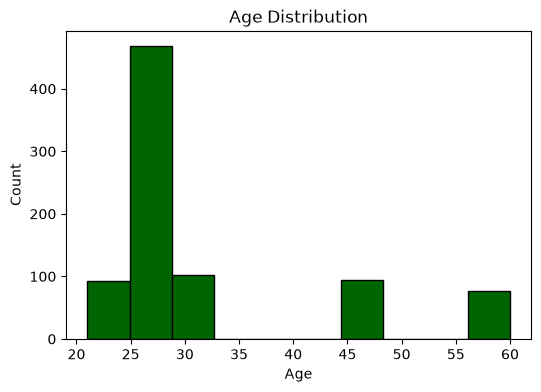

In [222]:
plt.figure(figsize=(6,4))
plt.hist(df["Age"], bins=10, color="darkgreen", edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

## Revenue by Product-category

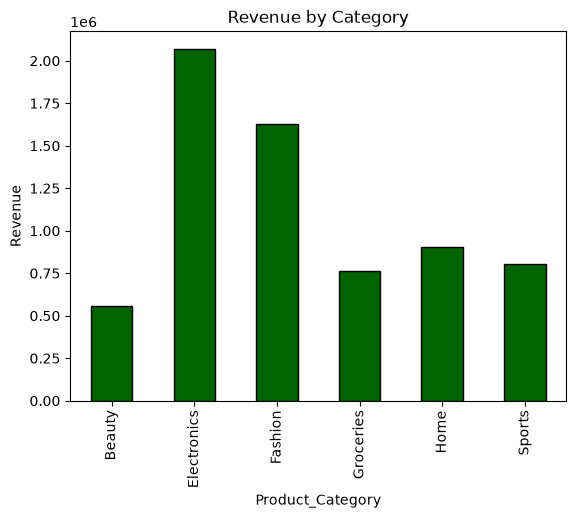

In [223]:
df.groupby("Product_Category")["Revenue"].sum().plot(
    kind="bar",
    color="darkgreen",
    edgecolor="black"
)

plt.title("Revenue by Category")
plt.xlabel("Product_Category")
plt.ylabel("Revenue")
plt.show()

### Payment Method distribution

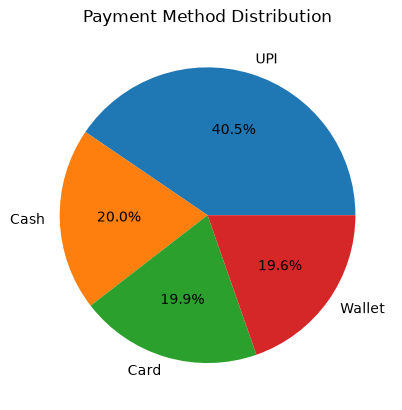

In [224]:
df["Payment_Method"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Payment Method Distribution")
plt.ylabel("")
plt.show()


### Customer Rating

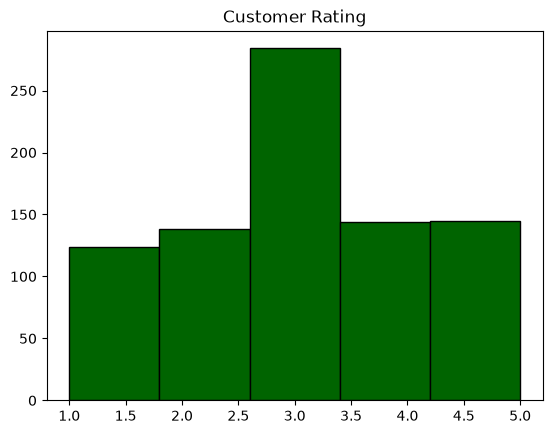

In [225]:
plt.hist(df["Customer_Rating"], bins=5, edgecolor="black", color="darkgreen")
plt.title("Customer Rating")
plt.show()

## Unit Price v/s Revenue

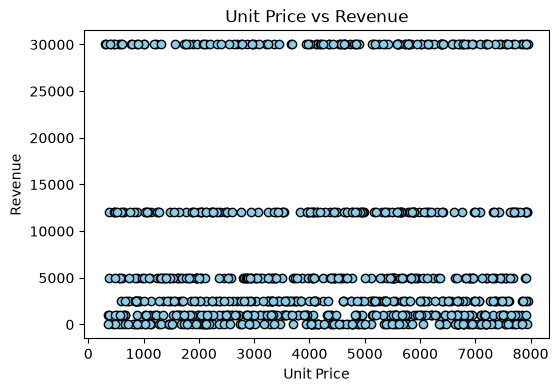

In [226]:
plt.figure(figsize=(6,4))
plt.scatter(df["Unit_Price"], df["Revenue"], color="skyblue", edgecolors="black", )
plt.title("Unit Price vs Revenue")
plt.xlabel("Unit Price")
plt.ylabel("Revenue")
plt.show()

## Top 10 cities by numbers of orders.

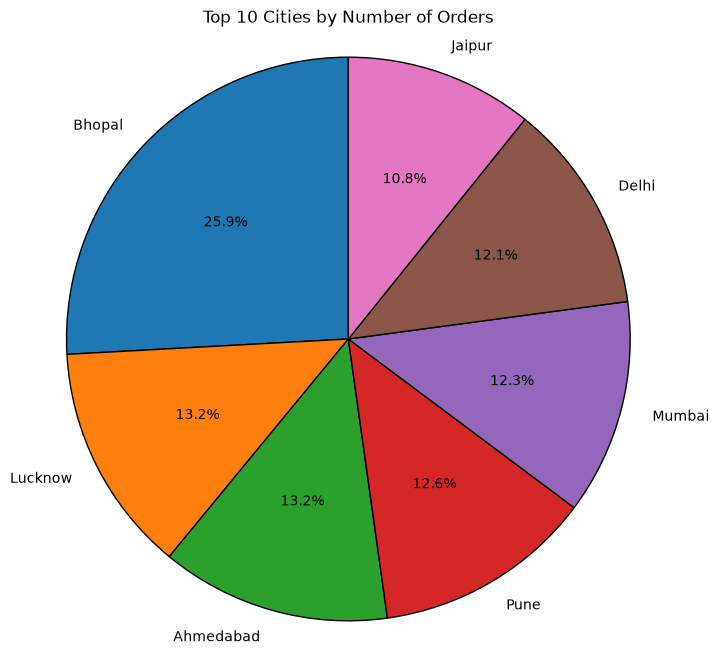

In [227]:
# Top 10 Cities by Number of Orders
city = df["City"].value_counts().head(10)

plt.figure(figsize=(8,8))
plt.pie(
    city,
    labels=city.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "black"}
)

plt.title("Top 10 Cities by Number of Orders")
plt.axis("equal")   # Makes the pie chart circular
plt.show()

## Box plot of Unit Price

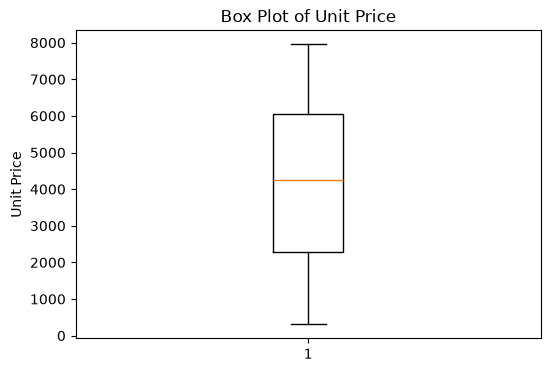

In [228]:
plt.figure(figsize=(6,4))
plt.boxplot(df["Unit_Price"])
plt.title("Box Plot of Unit Price")
plt.ylabel("Unit Price")
plt.show()

## Revenue by Quantity 

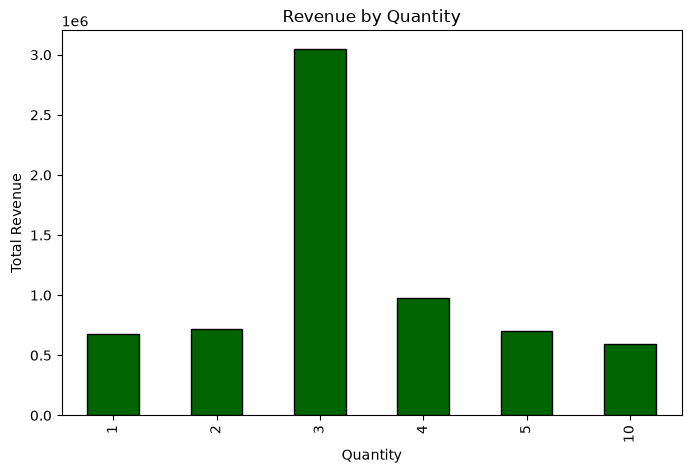

In [229]:
quantity_revenue = df.groupby("Quantity")["Revenue"].sum()

plt.figure(figsize=(8,5))
quantity_revenue.plot(
    kind="bar",
    color="darkgreen",
    edgecolor="black"
)

plt.title("Revenue by Quantity")
plt.xlabel("Quantity")
plt.ylabel("Total Revenue")
plt.show()

### Marketing channel distribution

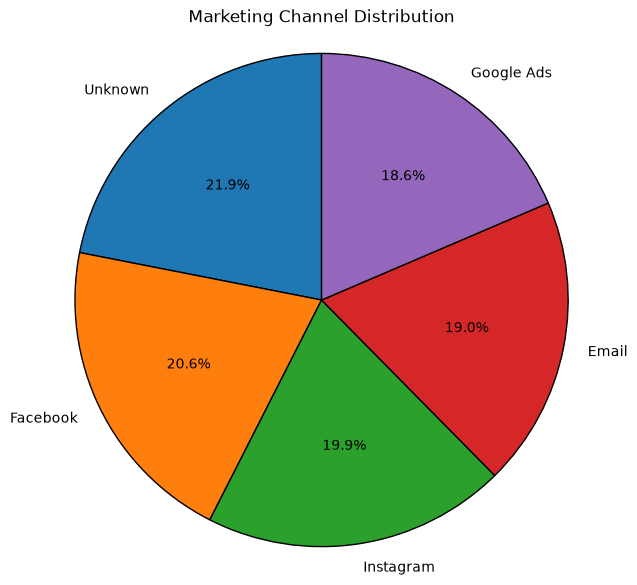

In [230]:
marketing = df["Marketing_Channel"].value_counts()

plt.figure(figsize=(7,7))
plt.pie(
    marketing,
    labels=marketing.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "black"}
)

plt.title("Marketing Channel Distribution")
plt.axis("equal")  # Makes the pie chart a perfect circle
plt.show()

In [231]:
df.to_csv("cleaned_ecommerce_data.csv")

In [233]:
print(df.shape)


(835, 17)
